### ASTR 3300/5300: Astrostatistics
***N. Pol***
___

# Final Exam [65 points total]

### Due: Tuesday, 24 November, 2026, 11:59 pm. NO EXTENSIONS, NO SUBMISSION ACCEPTED PAST DUE DATE/TIME.
---

## Problem 1 [30 points total]

One of the most important revelations in modern cosmology was the accelerated expansion of the Universe, interpreted as being caused by a non-zero Cosmological Constant. In this question you will use a simulated sample of Type Ia supernovae to infer the composition of the Universe. 

1. Load in `astr8070_final_cosmodata.npy`, which can be found in the Github repo under `coursework/final/final_data`. The first column is the SN redshift, the second is the distance modulus, and the third is the Gaussian uncertainty on this distance modulus. Make a labeled scatter plot of the data. [2 points]


2. Plot a line on top of this showing the relationship between the distance modulus and the redshift for the current concordance cosmology. You will need to look up the definition of the distance modulus, look up current reasonable cosmological parameters (cite your source), and plot the relationship. *Hint: check astropy.* [3 points]


3. Create a log-likelihood function that reads in the data and accepts values for the Hubble constant, $H_0$, and the fractional energy density in matter, $\Omega_M$. Assume a flat cosmological geometry, such that $\Omega_M + \Omega_\Lambda=1$. Your function should take $H_0$ and $\Omega_M$, and create a model for the distance moduli values at the redshifts of the samples, then compute the log-likelihood for the data. Print out the log-likelihood value at the cosmological parameter values that you used in (2). For maximum points, make sure your log-likelihood function is vectorized over the data samples. [6 points]


4. Perform an MCMC with appropriate diagnostic checks (either manually yourself, or fine if performed by the sampler you employ) over the $\{H_0, \Omega_M\}$ parameter space. Assume priors of $H_0 \in U[50,100]$ km.s$^{-1}$.Mpc$^{-1}$, and $\Omega_M \in U[0,1]$. Make a labeled corner plot showing the $1$D and $2$D marginalized posterior probability distribution of these parameters. State the median value of the $1$D marginal posteriors for each, along with the values enclosing the $68\%$ credible region. [8 points]


5. Draw $100$ random samples from your posterior chain and plot the corresponding band of solutions that are consistent with the data on the distance-modulus--vs--redshift plot along with the original data. [4 points]


6. Now, using an appropriate technique, find the Bayesian log-evidence of your $\{H_0,\Omega_M\}$ model above. Also find the log-evidence of a model with $\Omega_M=1$ such that $H_0$ is the only varied parameter. What is the Bayes factor for the presence of a Cosmological Constant given these data? [7 points] 

**Problem 1**

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [106]:
data = np.load('final_data/astr8070_final_cosmodata.npy')

z = data[:, 0]
distance_mod = data[:, 1]
Gauss_err = data[:, 2]

print(data.shape)

(200, 3)


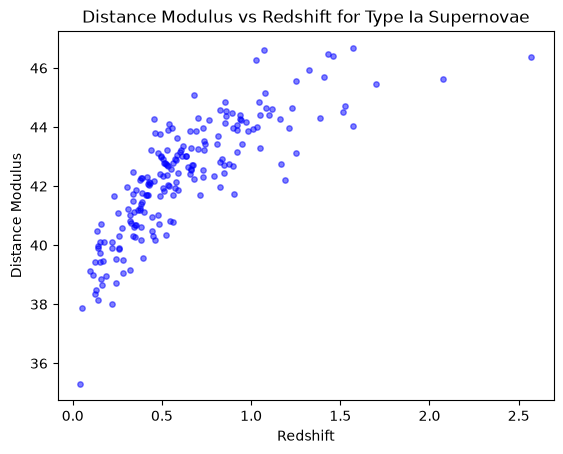

In [107]:
plt.scatter(z, distance_mod, s=15, color = 'blue', alpha = 0.5)
plt.xlabel('Redshift')
plt.ylabel('Distance Modulus')
plt.title('Distance Modulus vs Redshift for Type Ia Supernovae')
plt.show()

In [108]:
from astropy.cosmology import Planck18

In [109]:
theor_dist = Planck18.distmod(z).value

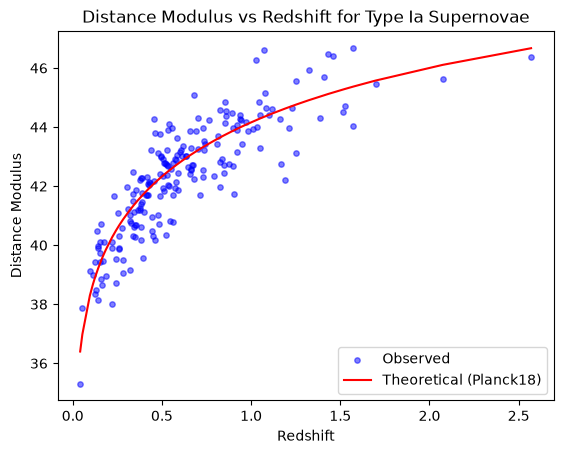

In [110]:
idx = np.argsort(z)

plt.scatter(z, distance_mod,  s=15, color = 'blue', alpha = 0.5, label = 'Observed')
plt.plot(z[idx], theor_dist[idx], '-', color = 'red', label = 'Theoretical (Planck18)')
plt.xlabel('Redshift')
plt.ylabel('Distance Modulus')
plt.title('Distance Modulus vs Redshift for Type Ia Supernovae')
plt.legend()
plt.show()

**Reference:** Planck Collaboration et al. (2020), *Planck 2018 results. VI. Cosmological parameters*, Astronomy & Astrophysics, 641, A6. https://doi.org/10.1051/0004-6361/201833910

The Planck18 cosmological model was accessed through the Astropy documentation: https://docs.astropy.org/en/stable/cosmology/realizations.html

In [7]:
from astropy.cosmology import FlatLambdaCDM

In [8]:
cosm_const = FlatLambdaCDM(H0 = 67.66, Om0 = 0.30966)

In [9]:
theor_dist1 = cosm_const.distmod(z).value

In [10]:
residual = distance_mod - theor_dist1

In [11]:
log_likelihood = -0.5*np.sum((residual/Gauss_err)**2 + np.log(2*np.pi*Gauss_err**2))

print('Log Likelihood:', log_likelihood)

Log Likelihood: -268.01593953112905


In [12]:
def log_likelihood(H0, Om0):
    data = np.load('/Users/jhorna/astrostats_ttu_fall26/coursework/student_folders/Jhorna_Akter/final/final_data/astr8070_final_cosmodata.npy')
    z = data[:, 0]
    distance_mod = data[:, 1]
    Gauss_err = data[:, 2]

    cosm_const1 = FlatLambdaCDM(H0 = H0, Om0 = Om0)
    theor_dist2 = cosm_const1.distmod(z).value
    residual = distance_mod - theor_dist2
    return  -0.5*np.sum((residual/Gauss_err)**2 + np.log(2*np.pi*Gauss_err**2))

In [13]:
print(log_likelihood(67.66, 0.30966)) #just to test if the function work properly

-268.01593953112905


In [14]:
def log_prior(H0, Om0):
    if 50 <= H0 <= 100 and 0 <= Om0 <= 1:
        return 0.0
    return -np.inf

In [15]:
def log_posterior(H0, Om0):
    l_prior=log_prior(H0, Om0)
    if not np.isfinite(l_prior):
        return -np.inf
    return l_prior + log_likelihood(H0, Om0)

In [16]:
import emcee

In [17]:
def log_prob(theta):
    H0, Om0 = theta
    return log_posterior(H0, Om0)

In [18]:
ndim =2
nwalkers = 32

initial = np.array([67.66, 0.30966])
positions = initial+1e-3*np.random.randn(nwalkers, ndim)

In [19]:
sampler = emcee.EnsembleSampler(nwalkers, ndim, log_prob)
sampler.run_mcmc(positions, 5000, progress = True);

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 5000/5000 [08:55<00:00,  9.33it/s]


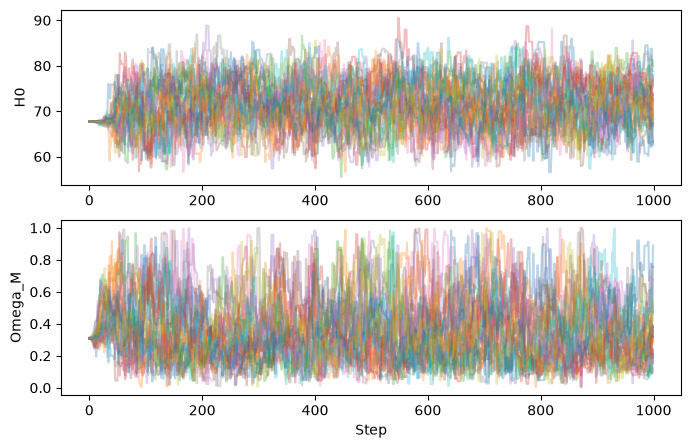

In [20]:
samples = sampler.get_chain()

fig, ax = plt.subplots(2, 1, figsize=(8, 5))

ax[0].plot(samples[:1000, :, 0], alpha=0.3)
ax[0].set_ylabel('H0')

ax[1].plot(samples[:1000, :, 1], alpha=0.3)
ax[1].set_ylabel('Omega_M')
ax[1].set_xlabel('Step')

plt.show()

In [21]:
tau = sampler.get_autocorr_time()
print(tau)

[35.8820639 35.1768795]


In [22]:
flat_samples = sampler.get_chain(discard=200, thin=19, flat=True)

print(flat_samples.shape)

(8064, 2)


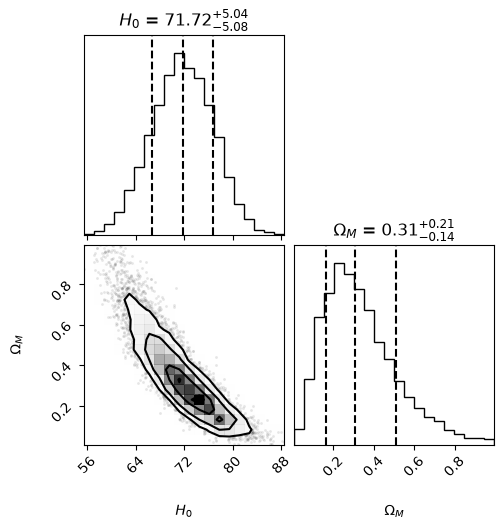

In [23]:
import corner

corner.corner(
    flat_samples,
    labels=[r'$H_0$', r'$\Omega_M$'],
    show_titles=True,
    quantiles=[0.16, 0.5, 0.84]
)

plt.show()

In [24]:
for i, name in enumerate(['H0', 'Omega_M']):
    q16, q50, q84 = np.percentile(flat_samples[:, i], [16, 50, 84])
    print(f'{name} = {q50:.2f} +{q84-q50:.2f} -{q50-q16:.2f}')

H0 = 71.72 +5.04 -5.08
Omega_M = 0.31 +0.21 -0.14


In [25]:
indices = np.random.choice(len(flat_samples), 100, replace = 'false')
random_samples = flat_samples[indices]

print(random_samples.shape)

(100, 2)


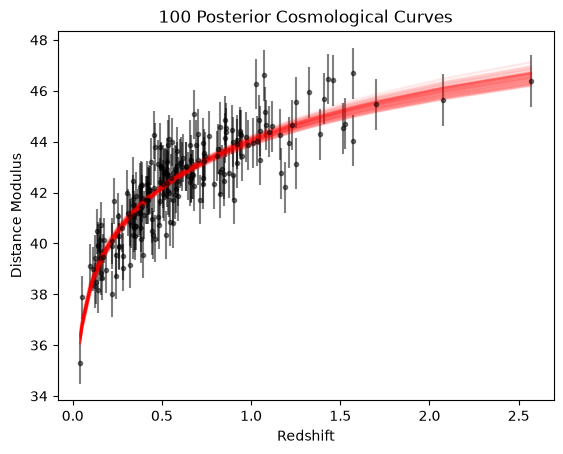

In [26]:
plt.errorbar(z, distance_mod, yerr = Gauss_err, fmt = '.', color = 'black', alpha = 0.5) #just to show the error in every point

for H0, Om0 in random_samples:
    cosm_const3 = FlatLambdaCDM(H0=H0, Om0=Om0)
    theor_dist3 = cosm_const3.distmod(z).value
    plt.plot(z[idx], theor_dist3[idx], color = 'red', alpha = 0.05)

plt.xlabel('Redshift')
plt.ylabel('Distance Modulus')
plt.title('100 Posterior Cosmological Curves')
plt.show()

In [27]:
H0_grid = np.linspace(50, 100, 100)
Om0_grid = np.linspace(0, 1, 100)

logL = np.array([
    [log_likelihood(H0, Om0) for Om0 in Om0_grid]
    for H0 in H0_grid
])

In [28]:
from scipy.integrate import trapezoid

max_logL = np.max(logL)
L_scaled = np.exp(logL - max_logL)

integral_Om = trapezoid(L_scaled, Om0_grid, axis=1)
integral_H0 = trapezoid(integral_Om, H0_grid)

logZ1 = max_logL + np.log(integral_H0 / 50)

print("Model 1 log-evidence =", logZ1)

Model 1 log-evidence = -269.3328570928798


In [29]:
logL2 = np.array([log_likelihood(H0, 1) for H0 in H0_grid])

max_logL2 = np.max(logL2)
L_scaled2 = np.exp(logL2 - max_logL2)

integral2 = trapezoid(L_scaled2, H0_grid)

logZ2 = max_logL2 + np.log(integral2 / 50)

print("Model 2 log-evidence =", logZ2)

Model 2 log-evidence = -272.1733049954867


In [30]:
logB = logZ1 - logZ2
B = np.exp(logB)

print("Log Bayes factor =", logB)
print("Bayes factor =", B)

Log Bayes factor = 2.840447902606911
Bayes factor = 17.12343345026019


## 
Problem 2 [35 points total]

There are several empirical scaling relationships between the masses of black holes in galaxy centers and the properties of their hosts. In this problem you will use real data from the "MASSIVE" Galaxy Survey. This data updates that used in [McConnell & Ma (2013)](https://ui.adsabs.harvard.edu/abs/2013ApJ...764..184M/abstract), which presented a systematic investigation of scaling relations with different catalog subsets.

1. Download this dataset: http://blackhole.berkeley.edu/wp-content/uploads/2016/09/current_ascii.txt. Skip the appropriate header rows and read this into a `pandas` dataframe. Use the meta-data in the header rows to create appropriate column names for your dataframe. Make sure that your data file is properly formatted with tab-spaced columns so that it is readable without errors. [3 points]


2. Create a data matrix out of the base-10 log values of: the galaxy distance, the velocity dispersion $\sigma$, and the black hole mass. Create a target vector that has $1$ for early-type galaxies (morphology has `E` or `S0` in the value) and $0$ for late-type galaxies. Print out the number of early-type and late-type galaxies that are in your target vector, as well as the total number of galaxies. [3 points]


3. Perform a 50-50 train-test split on the data matrix and target vector, using `random_state=0` for reproducibility. Train the following classifiers, overplotting ROC curves for all:
    - Gaussian Naive Bayes
    - LDA
    - QDA
    - $K$-nearest neighbors (with $K=10$)
    - Gaussian mixture model (with $2$ components)
    - Decision Tree (with `entropy` criterion, and tree depth $=2$)
 [5 points]
    

4. What minimum tree depth do you need to achieve essentially perfect classification accuracy with the Decision Tree? Confirm this by making a two-panel figure with scatter plots of the log10-distance and log10-sigma from the test data, color-coded by the test label (left panel) and predicted label (right panel).  [3 points]


5. The following regression tasks should all produce best-fit regression coefficients and a plot. State how many galaxies are being fit in each scenario.
    - Use the $68\%$ low and high black-hole mass values to deduce the uncertainty on each $(M_\mathrm{BH}/M_\odot)$. Convert this into an uncertainty on $\log_{10}(M_\mathrm{BH}/M_\odot)$. Ignoring the uncertainties on $\sigma$, perform linear regression of the form
$$ \log_{10}(M_\mathrm{BH}/M_\odot) = \alpha + \beta\log_{10}(\sigma \,/\, 200\,\mathrm{km.s}^{-1})$$
and state the best-fit regression coefficients $\{\alpha,\beta\}$. Plot the best-fit line on a scatter plot with the data. 
    - Repeat the previous bullet to fit and plot the relation $$ \log_{10}(M_\mathrm{BH}/M_\odot) = \alpha + \beta\log_{10}(L_V \,/\, 10^{11}L_\odot)$$ for the sub-sample of galaxies with $V$-band luminosity data (ignoring the $L_V$ uncertainties).
    - Repeat to fit and plot the relation $$ \log_{10}(M_\mathrm{BH}/M_\odot) = \alpha + \beta\log_{10}(M_\mathrm{bulge} \,/\, 10^{11}M_\odot)$$ for the sub-sample of galaxies with bulge mass measurements (ignoring the $M_\mathrm{bulge}$ uncertainties).
 [7 points]
 
 
6. Perform polynomial regression of the form
$$ \log_{10}(M_\mathrm{BH}/M_\odot) = \alpha + \sum_{p=1}^{N_p}\beta_p[\log_{10}(\sigma \,/\, 200\,\mathrm{km.s}^{-1})]^p.$$
For $N_p$ in the range $0$ to $5$, fit the polynomial relationship, print the regression coefficients, and compute the BIC value. Make a labeled plot of the BIC versus the polynomial degree. Is a quadratic or higher polynomial relationship between $\log_{10}(M_\mathrm{BH}/M_\odot)$ and $\log_{10}(\sigma \,/\, 200\,\mathrm{km.s}^{-1})$ favored? [5 points]


7. Perform linear regression ($N_p=1$) on the dataset on sub-samples of early-type and late-type galaxies. Print the best-fit regression coefficients from each of these sub-sets. Make a scatter plot that includes the original data color coded by early/late type, the fit to all of the data, and the fits from the early/late-type sub-samples. The plot should have appropriate labels and a legend. [4 points]

In [31]:
import pandas as pd

In [34]:
data2 = pd.read_csv("final_data/astr8070_final_mcma.txt", sep = r"\s+", skiprows = 25, header = None)
data2.columns = ["Galaxy", "Distance", "MBH", "MBH_lower",
                "MBH_upper", "Method", "sigma", "sigma_lower",
                "sigma_upper", "log_LV", "error_log_LV",
                "log_L36", "error_log_L36", "Mbulge",
                "radius_influence", "Morphology", "Profile",
                "Reff_V", "Reff_i", "Reff_36"]

data2.head()
data2.shape

(78, 20)

In [42]:
data2[["Distance", "sigma", "MBH"]].min() #Checking if any of these had negative values.

Distance          0.008
sigma            75.000
MBH         1600000.000
dtype: float64

In [43]:
X = np.log10(data2[["Distance", "sigma", "MBH"]].values)
X.shape

(78, 3)

In [44]:
data2["Morphology"].unique()

<StringArray>
['S', 'E', 'S0', 'E/S0', 'S0/E']
Length: 5, dtype: str

In [45]:
y = data2["Morphology"].str.contains("E|S0").astype(int).values

In [46]:
print("Early-type galaxies:", np.sum(y == 1))
print("Late-type galaxies:", np.sum(y == 0))
print("Total galaxies:", len(y))

Early-type galaxies: 59
Late-type galaxies: 19
Total galaxies: 78


In [48]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.5, random_state = 0)

print(X_train.shape)
print(y_train.shape)

(39, 3)
(39,)


In [49]:
from sklearn.naive_bayes import GaussianNB

gnb = GaussianNB()
gnb.fit(X_train, y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[ 9.,30.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.23,0.77]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](2,)","[0,1]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,1.041e-09
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 3)","[[0.72,2.11,7.1 ], [1.39,2.34,8.58]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 3)","[[1.07,0.01,0.32], [0.17,0.02,0.75]]"


In [50]:
y_probability_gnb = gnb.predict_proba(X_test)[:, 1]

In [52]:
from sklearn.metrics import roc_curve, auc

fpr_gnb, tpr_gnb, thresholds_gnb = roc_curve(y_test, y_probability_gnb)
auc_gnb = auc(fpr_gnb, tpr_gnb)

print(auc_gnb)

0.9275862068965518


In [53]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

lda = LinearDiscriminantAnalysis()

lda.fit(X_train, y_train)

,"solver solver: {'svd', 'lsqr', 'eigen'}, default='svd'Solver to use, possible values: - 'svd': Singular value decomposition (default). Does not compute the covariance matrix, therefore this solver is recommended for data with a large number of features. - 'lsqr': Least squares solution. Can be combined with shrinkage or custom covariance estimator. - 'eigen': Eigenvalue decomposition. Can be combined with shrinkage or custom covariance estimator... versionchanged:: 1.2 `solver=""svd""` now has experimental Array API support. See the :ref:`Array API User Guide <array_api>` for more details.",'svd'
,"shrinkage shrinkage: 'auto' or float, default=NoneShrinkage parameter, possible values: - None: no shrinkage (default). - 'auto': automatic shrinkage using the Ledoit-Wolf lemma. - float between 0 and 1: fixed shrinkage parameter.This should be left to None if `covariance_estimator` is used.Note that shrinkage works only with 'lsqr' and 'eigen' solvers.For a usage example, see:ref:`sphx_glr_auto_examples_classification_plot_lda.py`.",None
,"priors priors: array-like of shape (n_classes,), default=NoneThe class prior probabilities. By default, the class proportions areinferred from the training data.",None
,"n_components n_components: int, default=NoneNumber of components (<= min(n_classes - 1, n_features)) fordimensionality reduction. If None, will be set tomin(n_classes - 1, n_features). This parameter only affects the`transform` method.For a usage example, see:ref:`sphx_glr_auto_examples_decomposition_plot_pca_vs_lda.py`.",None
,"store_covariance store_covariance: bool, default=FalseIf True, explicitly compute the weighted within-class covariancematrix when solver is 'svd'. The matrix is always computedand stored for the other solvers... versionadded:: 0.17",False
,"tol tol: float, default=1.0e-4Absolute threshold for a singular value of X to be consideredsignificant, used to estimate the rank of X. Dimensions whosesingular values are non-significant are discarded. Only used ifsolver is 'svd'... versionadded:: 0.17",0.0001
,"covariance_estimator covariance_estimator: covariance estimator, default=NoneIf not None, `covariance_estimator` is used to estimatethe covariance matrices instead of relying on the empiricalcovariance estimator (with potential shrinkage).The object should have a fit method and a ``covariance_`` attributelike the estimators in :mod:`sklearn.covariance`.if None the shrinkage parameter drives the estimate.This should be left to None if `shrinkage` is used.Note that `covariance_estimator` works only with 'lsqr' and 'eigen'solvers... versionadded:: 0.24",None
Name,Type,Value
"classes_ classes_: array-like of shape (n_classes,)Unique class labels.","ndarray[int64](2,)","[0,1]"
"coef_ coef_: ndarray of shape (n_features,) or (n_classes, n_features)Weight vector(s).","ndarray[float64](1, 3)","[[ 0.27,-1.02, 2.33]]"
"explained_variance_ratio_ explained_variance_ratio_: ndarray of shape (n_components,)Percentage of variance explained by each of the selected components.If ``n_components`` is not set then all components are stored and thesum of explained variances is equal to 1.0. Only available when eigenor svd solver is used.","ndarray[float64](1,)",[1.]


In [54]:
y_probability_lda = lda.predict_proba(X_test)[:, 1]

In [56]:
fpr_lda, tpr_lda, thresholds_gnb = roc_curve(y_test, y_probability_lda)
auc_lda = auc(fpr_lda, tpr_lda)

print(auc_lda)

0.9


In [57]:
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis

qda = QuadraticDiscriminantAnalysis()

qda.fit(X_train, y_train)

,"solver solver: {'svd', 'eigen'}, default='svd'Solver to use, possible values: - 'svd': Singular value decomposition (default). Does not compute the covariance matrix, therefore this solver is recommended for data with a large number of features. - 'eigen': Eigenvalue decomposition. Can be combined with shrinkage or custom covariance estimator.",'svd'
,"shrinkage shrinkage: 'auto' or float, default=NoneShrinkage parameter, possible values: - None: no shrinkage (default). - 'auto': automatic shrinkage using the Ledoit-Wolf lemma. - float between 0 and 1: fixed shrinkage parameter. Enabling shrinkage is expected to improve the model when some classes have a relatively small number of training data points compared to the number of features by mitigating overfitting during the covariance estimation step.This should be left to `None` if `covariance_estimator` is used.Note that shrinkage works only with 'eigen' solver.",None
,"priors priors: array-like of shape (n_classes,), default=NoneClass priors. By default, the class proportions are inferred from thetraining data.",None
,"reg_param reg_param: float, default=0.0Regularizes the per-class covariance estimates by transforming S2 as``S2 = (1 - reg_param) * S2 + reg_param * np.eye(n_features)``,where S2 corresponds to the `scaling_` attribute of a given class.",0.0
,"store_covariance store_covariance: bool, default=FalseIf True, the class covariance matrices are explicitly computed andstored in the `self.covariance_` attribute... versionadded:: 0.17",False
,"tol tol: float, default=1.0e-4Absolute threshold for the covariance matrix to be considered rankdeficient after applying some regularization (see `reg_param`) to each`Sk` where `Sk` represents covariance matrix for k-th class. Thisparameter does not affect the predictions. It controls when a warningis raised if the covariance matrix is not full rank... versionadded:: 0.17",0.0001
,"covariance_estimator covariance_estimator: covariance estimator, default=NoneIf not None, `covariance_estimator` is used to estimate the covariancematrices instead of relying on the empirical covariance estimator(with potential shrinkage). The object should have a fit method anda ``covariance_`` attribute like the estimators in:mod:`sklearn.covariance`. If None the shrinkage parameter drives theestimate.This should be left to `None` if `shrinkage` is used.Note that `covariance_estimator` works only with the 'eigen' solver.",None
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)Unique class labels.","ndarray[int64](2,)","[0,1]"
"means_ means_: array-like of shape (n_classes, n_features)Class-wise means.","ndarray[float64](2, 3)","[[0.72,2.11,7.1 ], [1.39,2.34,8.58]]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3


In [58]:
y_probability_qda = qda.predict_proba(X_test)[:, 1]

In [60]:
fpr_qda, tpr_qda, thresholds_qda = roc_curve(y_test, y_probability_qda)
auc_qda = auc(fpr_qda, tpr_qda)

print(auc_qda)

0.9275862068965517


In [61]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier()

knn.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [63]:
y_probability_knn = knn.predict_proba(X_test)[:, 1]

In [64]:
fpr_knn, tpr_knn, thresholds_knn = roc_curve(y_test, y_probability_knn)
auc_knn = auc(fpr_knn, tpr_knn)

print(auc_knn)

0.8310344827586207


In [65]:
from sklearn.mixture import GaussianMixture

gmm = GaussianMixture(n_components = 2, random_state = 0)
gmm.fit(X_train)

,"n_components n_components: int, default=1The number of mixture components.",2
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to the method chosen to initialize theparameters (see `init_params`).In addition, it controls the generation of random samples from thefitted distribution (see the method `sample`).Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",0
,"covariance_type covariance_type: {'full', 'tied', 'diag', 'spherical'}, default='full'String describing the type of covariance parameters to use.Must be one of:- 'full': each component has its own general covariance matrix.- 'tied': all components share the same general covariance matrix.- 'diag': each component has its own diagonal covariance matrix.- 'spherical': each component has its own single variance.For an example of using `covariance_type`, refer to:ref:`sphx_glr_auto_examples_mixture_plot_gmm_selection.py`.",'full'
,"tol tol: float, default=1e-3The convergence threshold. EM iterations will stop when thelower bound average gain is below this threshold.",0.001
,"reg_covar reg_covar: float, default=1e-6Non-negative regularization added to the diagonal of covariance.Allows to assure that the covariance matrices are all positive.",1e-06
,"max_iter max_iter: int, default=100The number of EM iterations to perform.",100
,"n_init n_init: int, default=1The number of initializations to perform. The best results are kept.",1
,"init_params init_params: {'kmeans', 'k-means++', 'random', 'random_from_data'}, default='kmeans'The method used to initialize the weights, the means and theprecisions.String must be one of:- 'kmeans' : responsibilities are initialized using kmeans.- 'k-means++' : use the k-means++ method to initialize.- 'random' : responsibilities are initialized randomly.- 'random_from_data' : initial means are randomly selected data points... versionchanged:: v1.1 `init_params` now accepts 'random_from_data' and 'k-means++' as initialization methods.",'kmeans'
,"weights_init weights_init: array-like of shape (n_components, ), default=NoneThe user-provided initial weights.If it is None, weights are initialized using the `init_params` method.",None
,"means_init means_init: array-like of shape (n_components, n_features), default=NoneThe user-provided initial means,If it is None, means are initialized using the `init_params` method.",None
,"precisions_init precisions_init: array-like, default=NoneThe user-provided initial precisions (inverse of the covariancematrices).If it is None, precisions are initialized using the 'init_params'method.The shape depends on 'covariance_type':: (n_components,) if 'spherical', (n_features, n_features) if 'tied', (n_components, n_features) if 'diag', (n_components, n_features, n_features) if 'full'",None


In [66]:
gmm_labels = gmm.predict(X_train)
pd.crosstab(gmm_labels, y_train)

col_0,0,1
row_0,,
0,7,29
1,2,1


In [67]:
y_prob_gmm = gmm.predict_proba(X_test)[:, 0]

fpr_gmm, tpr_gmm, thresholds_gmm = roc_curve(y_test, y_prob_gmm)

auc_gmm = auc(fpr_gmm, tpr_gmm)

print(auc_gmm)

0.5


In [68]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(criterion = "entropy", max_depth = 2, random_state = 0)
dt.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",2
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",0
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples 

In [72]:
y_probability_dt = dt.predict_proba(X_test)[:, 1]

In [73]:
fpr_dt, tpr_dt, thresholds_dt = roc_curve(y_test, y_probability_dt)
auc_dt = auc(fpr_dt, tpr_dt)

print(auc_dt)

0.8517241379310345


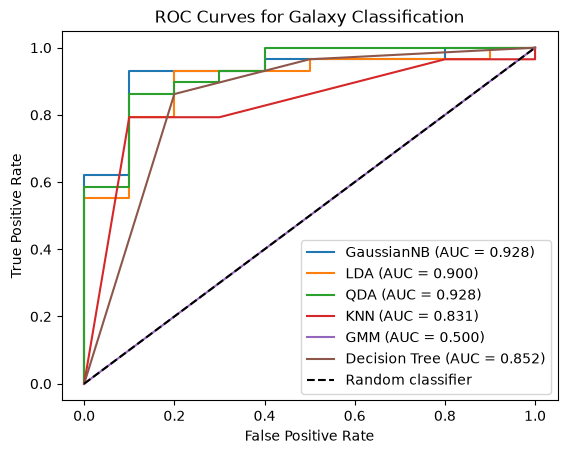

In [74]:
plt.plot(fpr_gnb, tpr_gnb, label=f"GaussianNB (AUC = {auc_gnb:.3f})")
plt.plot(fpr_lda, tpr_lda, label=f"LDA (AUC = {auc_lda:.3f})")
plt.plot(fpr_qda, tpr_qda, label=f"QDA (AUC = {auc_qda:.3f})")
plt.plot(fpr_knn, tpr_knn, label=f"KNN (AUC = {auc_knn:.3f})")
plt.plot(fpr_gmm, tpr_gmm, label=f"GMM (AUC = {auc_gmm:.3f})")
plt.plot(fpr_dt, tpr_dt, label=f"Decision Tree (AUC = {auc_dt:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves for Galaxy Classification")
plt.legend()
plt.show()

In [75]:
from sklearn.metrics import accuracy_score

for depth in range(1, 11):
    tree = DecisionTreeClassifier(criterion="entropy",
                                  max_depth=depth, random_state=0)
    tree.fit(X_train, y_train)
    y_pred = tree.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    print("Depth:", depth, "Accuracy:", accuracy)

Depth: 1 Accuracy: 0.8461538461538461
Depth: 2 Accuracy: 0.8461538461538461
Depth: 3 Accuracy: 0.8461538461538461
Depth: 4 Accuracy: 0.8461538461538461
Depth: 5 Accuracy: 0.8717948717948718
Depth: 6 Accuracy: 0.8717948717948718
Depth: 7 Accuracy: 0.8717948717948718
Depth: 8 Accuracy: 0.8717948717948718
Depth: 9 Accuracy: 0.8717948717948718
Depth: 10 Accuracy: 0.8717948717948718


In [76]:
tree = DecisionTreeClassifier(criterion="entropy", random_state=0) #Just trying to see how much depth it may reach.
tree.fit(X_train, y_train)

print(tree.get_depth())
print(tree.score(X_test, y_test))

5
0.8717948717948718


In [77]:
y_pred = tree.predict(X_test)

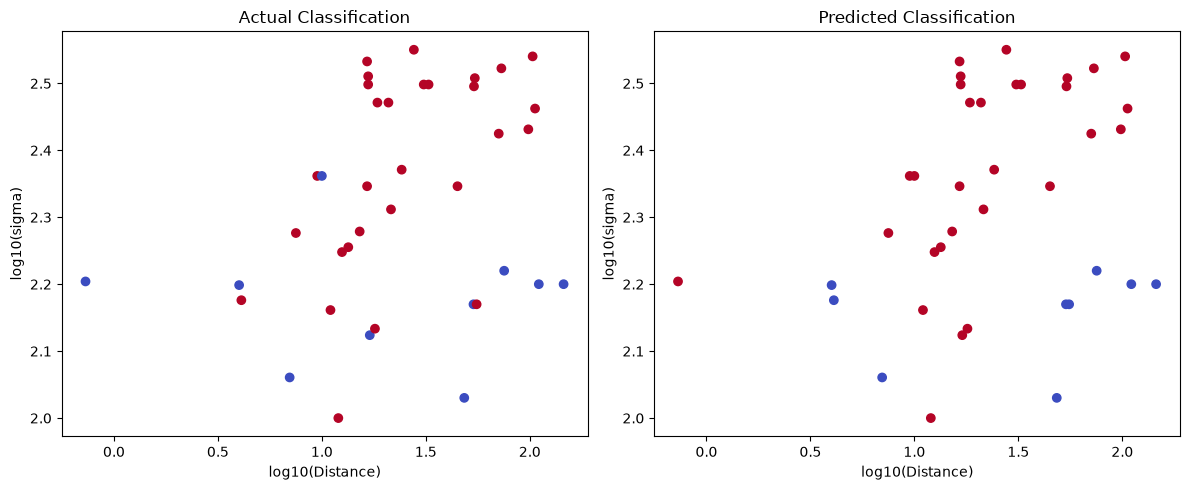

In [80]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap="coolwarm")
ax[0].set_title("Actual Classification")
ax[0].set_xlabel("log10(Distance)")
ax[0].set_ylabel("log10(sigma)")

ax[1].scatter(X_test[:, 0], X_test[:, 1], c=y_pred, cmap="coolwarm")
ax[1].set_title("Predicted Classification")
ax[1].set_xlabel("log10(Distance)")
ax[1].set_ylabel("log10(sigma)")

plt.tight_layout()
plt.show()

The decision tree achieves its highest testing accuracy of 87.18% at a minimum depth of 5. Increasing the tree depth does not improve the accuracy further. The two scatter plots show that most galaxies are correctly classified, although perfect classification is not achieved.

In [81]:
MBH = data2["MBH"].values

MBH_error = (data2["MBH_upper"].values - data2["MBH_lower"].values)/2

The uncertainty in black hole mass is approximated as

$$
\Delta M_{\rm BH} =
\frac{M_{\rm upper}-M_{\rm lower}}{2}.
$$

Since we use the logarithmic mass in our regression, we
convert its uncertainty using error propagation.

From the first-order Taylor expansion,

$$
f(x+\Delta x)\approx f(x)+f'(x)\Delta x,
$$

we obtain

$$
\Delta f\approx |f'(x)|\Delta x.
$$

For $f(x)=\log_{10}(x)$,

$$
f'(x)=\frac{1}{x\ln(10)}.
$$

Therefore, the logarithmic uncertainty is

$$
\Delta\log_{10}(M_{\rm BH}/M_\odot)
\approx
\frac{\Delta M_{\rm BH}}{M_{\rm BH}\ln(10)}.
$$


In [83]:
log_MBH = np.log10(MBH)

log_MBH_error = MBH_error / (MBH * np.log(10))

x_sigma = np.log10(data2["sigma"].values / 200)

In [84]:
beta, alpha = np.polyfit(x_sigma, log_MBH, 1,
                        w=1/log_MBH_error)      #just seeing how the weighted regression fit would look like.

print("alpha =", alpha)
print("beta =", beta)
print("Number of galaxies:", len(x_sigma))

alpha = 8.009500144334487
beta = 2.0895651441842595
Number of galaxies: 78


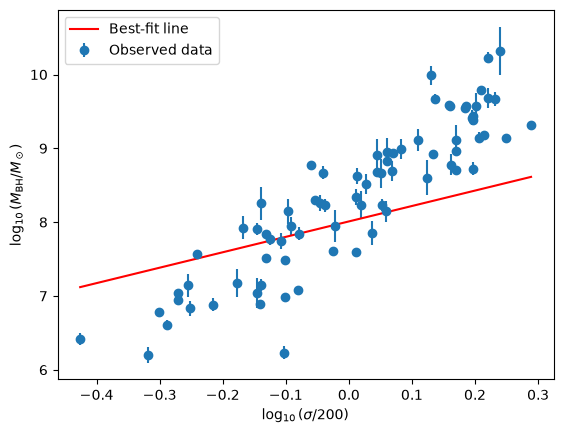

In [85]:
x_fit = np.linspace(min(x_sigma), max(x_sigma), 100)
y_fit = alpha + beta*x_fit

plt.errorbar(x_sigma, log_MBH, yerr=log_MBH_error,
             fmt="o", label="Observed data")

plt.plot(x_fit, y_fit, color="red", label="Best-fit line")

plt.xlabel(r"$\log_{10}(\sigma/200)$")
plt.ylabel(r"$\log_{10}(M_{\rm BH}/M_\odot)$")
plt.legend()
plt.show()

In [86]:
beta_unw, alpha_unw = np.polyfit(x_sigma, log_MBH, 1) #Just wanted to see how unweighted regression would fit

print("alpha =", alpha_unw)
print("beta =", beta_unw)

alpha = 8.307679304000963
beta = 5.469790270464522


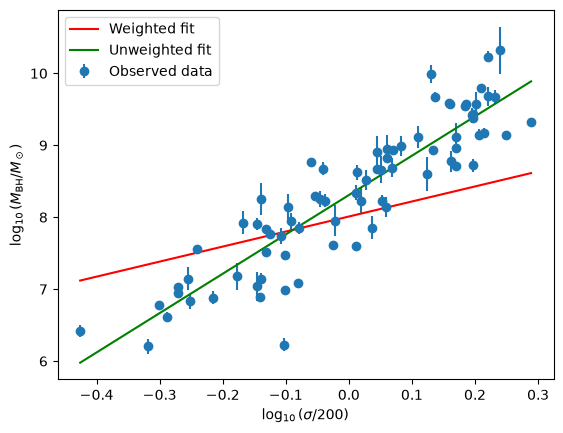

In [87]:
plt.errorbar(x_sigma, log_MBH, yerr=log_MBH_error,
             fmt="o", label="Observed data")

plt.plot(x_fit, alpha + beta*x_fit,
         color="red", label="Weighted fit")

plt.plot(x_fit, alpha_unw + beta_unw*x_fit,
         color="green", label="Unweighted fit")

plt.xlabel(r"$\log_{10}(\sigma/200)$")
plt.ylabel(r"$\log_{10}(M_{\rm BH}/M_\odot)$")
plt.legend()
plt.show()

Since the question asks us to calculate the uncertainty in black hole mass but does not explicitly specify whether to use weighted or unweighted linear regression, I performed both. The unweighted regression appears to follow the overall trend of the data better. Therefore, I use ordinary linear regression and include the calculated uncertainties as error bars in the plot.

In [88]:
data_LV = data2[data2["log_LV"] != 0]

print("Number of galaxies:", len(data_LV))

Number of galaxies: 48


In [89]:
x_LV = data_LV["log_LV"].values - 11
y_LV = np.log10(data_LV["MBH"].values)

In [90]:
beta_LV, alpha_LV = np.polyfit(x_LV, y_LV, 1)

print("alpha =", alpha_LV)
print("beta =", beta_LV)
print("Number of galaxies:", len(x_LV))

alpha = 9.273515346036701
beta = 1.116144573447784
Number of galaxies: 48


In [91]:
MBH_error_LV = (data_LV["MBH_upper"].values -
                data_LV["MBH_lower"].values)/2

log_MBH_error_LV = MBH_error_LV / (data_LV["MBH"].values * np.log(10))

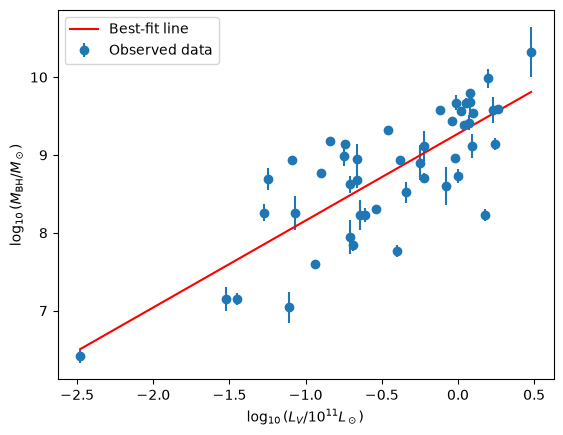

In [92]:
x_fit_LV = np.linspace(min(x_LV), max(x_LV), 100)
y_fit_LV = alpha_LV + beta_LV*x_fit_LV

plt.errorbar(x_LV, y_LV, yerr=log_MBH_error_LV,
             fmt="o", label="Observed data")

plt.plot(x_fit_LV, y_fit_LV, color="red", label="Best-fit line")

plt.xlabel(r"$\log_{10}(L_V/10^{11}L_\odot)$")
plt.ylabel(r"$\log_{10}(M_{\rm BH}/M_\odot)$")
plt.legend()
plt.show()

In [93]:
data_bulge = data2[data2["Mbulge"] > 0]

print("Number of galaxies:", len(data_bulge))

Number of galaxies: 38


In [94]:
x_bulge = np.log10(data_bulge["Mbulge"].values / 1e11)
y_bulge = np.log10(data_bulge["MBH"].values)

In [95]:
beta_bulge, alpha_bulge = np.polyfit(x_bulge, y_bulge, 1)

print("alpha =", alpha_bulge)
print("beta =", beta_bulge)
print("Number of galaxies:", len(x_bulge))

alpha = 8.56149130250634
beta = 0.8757692948669235
Number of galaxies: 38


In [96]:
MBH_error_bulge = (data_bulge["MBH_upper"].values -
                   data_bulge["MBH_lower"].values)/2

log_MBH_error_bulge = MBH_error_bulge / (data_bulge["MBH"].values * np.log(10))

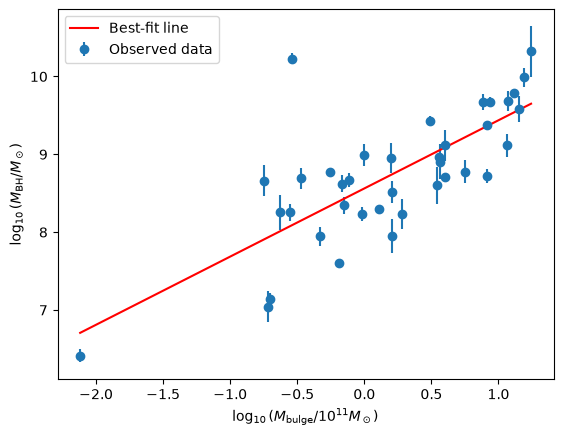

In [97]:
x_fit_bulge = np.linspace(min(x_bulge), max(x_bulge), 100)
y_fit_bulge = alpha_bulge + beta_bulge*x_fit_bulge

plt.errorbar(x_bulge, y_bulge, yerr=log_MBH_error_bulge,
             fmt="o", label="Observed data")

plt.plot(x_fit_bulge, y_fit_bulge, color="red", label="Best-fit line")

plt.xlabel(r"$\log_{10}(M_{\rm bulge}/10^{11}M_\odot)$")
plt.ylabel(r"$\log_{10}(M_{\rm BH}/M_\odot)$")
plt.legend()
plt.show()

In [98]:
for degree in range(6):
    coefficients = np.polyfit(x_sigma, log_MBH, degree)
    print("Degree:", degree)
    print("Coefficients:", coefficients)

Degree: 0
Coefficients: [8.3393998]
Degree: 1
Coefficients: [5.46979027 8.3076793 ]
Degree: 2
Coefficients: [1.30898871 5.53142314 8.27093809]
Degree: 3
Coefficients: [-10.64764556  -0.36537194   6.1037057    8.30195705]
Degree: 4
Coefficients: [-39.93939557 -20.83421561   2.60315871   6.49761581   8.27302647]
Degree: 5
Coefficients: [-183.14554735  -98.87287205   -2.64732475    6.5274154     6.07208711
    8.24176566]


In [100]:
N = len(log_MBH)
bic_values = []

for degree in range(6):
    coefficients = np.polyfit(x_sigma, log_MBH, degree)
    y_pred_poly = np.polyval(coefficients, x_sigma)
    RSS = np.sum((log_MBH - y_pred_poly)**2)
    k = degree + 2
   
    BIC = N*np.log(RSS/N) + k*np.log(N)
    bic_values.append(BIC)
    print("Degree:", degree, "BIC:", BIC)

Degree: 0 BIC: 10.184433363387939
Degree: 1 BIC: -117.10734475332973
Degree: 2 BIC: -113.36074015665415
Degree: 3 BIC: -110.475051005281
Degree: 4 BIC: -107.00080331885334
Degree: 5 BIC: -103.30737998327061


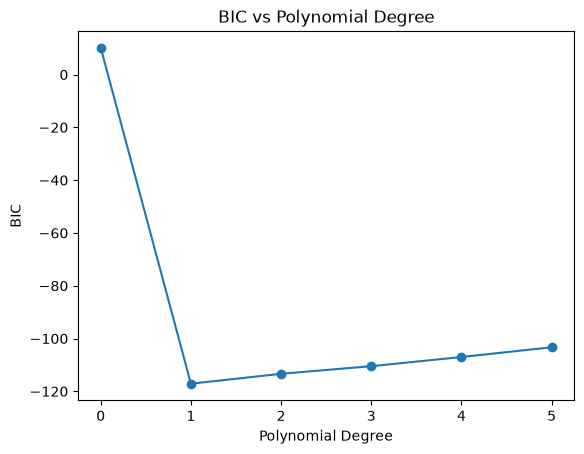

In [101]:
plt.plot(range(6), bic_values, marker='o')
plt.xlabel("Polynomial Degree")
plt.ylabel("BIC")
plt.xticks(range(6))
plt.title("BIC vs Polynomial Degree")
plt.show()

The polynomial of degree 1 has the lowest BIC. Therefore, a linear relationship between the logarithm of black hole mass and normalized logarithmic velocity dispersion is preferred. A quadratic or higher-degree polynomial relationship is not favored.

In [102]:
x_early = x_sigma[y == 1]
y_early = log_MBH[y == 1]

x_late = x_sigma[y == 0]
y_late = log_MBH[y == 0]

In [103]:
print("Early-type galaxies:", len(x_early))
print("Late-type galaxies:", len(x_late))

Early-type galaxies: 59
Late-type galaxies: 19


In [104]:
beta_early, alpha_early = np.polyfit(x_early, y_early, 1)
beta_late, alpha_late = np.polyfit(x_late, y_late, 1)

print("Early-type galaxies:")
print("Alpha:", alpha_early)
print("Beta:", beta_early)

print("Late-type galaxies:")
print("Alpha:", alpha_late)
print("Beta:", beta_late)

Early-type galaxies:
Alpha: 8.397439190792294
Beta: 5.040550431985342
Late-type galaxies:
Alpha: 7.909544098409623
Beta: 4.203547601585574


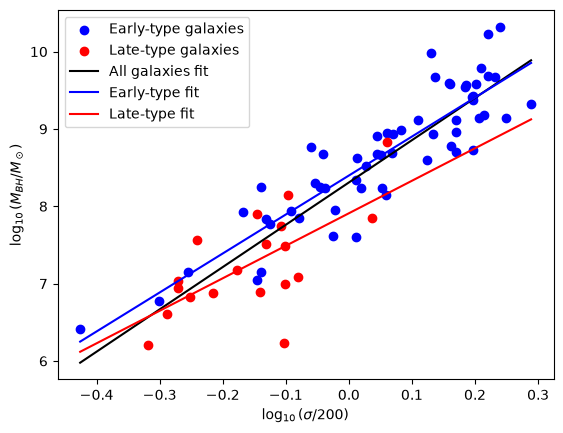

In [105]:
beta_all, alpha_all = np.polyfit(x_sigma, log_MBH, 1)

x_fit = np.linspace(min(x_sigma), max(x_sigma), 100)

plt.scatter(x_early, y_early, color='blue', label='Early-type galaxies')
plt.scatter(x_late, y_late, color='red', label='Late-type galaxies')

plt.plot(x_fit, alpha_all + beta_all*x_fit, color='black', label='All galaxies fit')
plt.plot(x_fit, alpha_early + beta_early*x_fit, color='blue', label='Early-type fit')
plt.plot(x_fit, alpha_late + beta_late*x_fit, color='red', label='Late-type fit')

plt.xlabel(r'$\log_{10}(\sigma/200)$')
plt.ylabel(r'$\log_{10}(M_{BH}/M_\odot)$')
plt.legend()
plt.show()